# DRD2 molecular docking with AutoDock Vina

This notebook prepares the DRD2 receptor, docks one configured example ligand, then attempts to dock the top 100 predicted compounds from each of the scaffold and random ZINC22 sets.

Run Jupyter with a Linux or macOS Python kernel; the dependency check explicitly rejects native Windows. WSL 2 with Ubuntu is the recommended Windows setup. Create and activate an environment with the packages used by the notebook:

```bash
conda create -n drd2-vina -c conda-forge vina meeko rdkit biopython pdbfixer openmm pandas matplotlib scipy jupyter
conda activate drd2-vina
```

Run the cells from top to bottom. The single-ligand example is fixed in the ligand cell below; it does not prompt for a path. The batch section expects `results/tables/scaffold_zinc22_predicted_pIC50.csv` and `results/tables/random_zinc22_predicted_pIC50.csv`, generated by `src/05_pIC50prediction.ipynb`. Outputs go to `docking/runs/`, `results/tables/`, and `results/figures/`.

In [54]:
from __future__ import annotations

import contextlib
import math
import shutil
import subprocess
import sys
import sysconfig
from pathlib import Path

## Settings

The receptor coordinates come from `data/processed/crystal_structures/6CM4_Na.mmcif`, a processed 6CM4 structure with the crystallographic oleic-acid molecules omitted and one artificial Na+ added. Receptor extraction keeps the DRD2 regions and excludes the T4 lysozyme fusion. The original PDBe structure is preserved at `data/raw/crystal_structures/6cm4.mmcif`; its co-crystallized risperidone (`8NU`) coordinates define the docking box. The ion coordinates and processing notes are in `data/processed/crystal_structures/README.md`.

In [55]:
ROOT = Path.cwd().resolve()
for parent in (ROOT, *ROOT.parents):
    if (parent / ".git").exists():
        ROOT = parent
        break
else:
    raise RuntimeError("Could not locate the project root (expected a .git directory).")

RUN_DIR = ROOT / "docking" / "runs"

PDB_ID = "6CM4"

RAW_STRUCTURE_PATH = ROOT / "data" / "raw" / "crystal_structures" / "6cm4.mmcif"
SODIUM_STRUCTURE_PATH = ROOT / "data" / "processed" / "crystal_structures" / "6CM4_Na.mmcif"
SHARED_RECEPTOR_DIR = ROOT / "docking" / "prepared" / "6CM4_Na"

RISPERIDONE_COMPONENT_ID = "8NU"

# The PDBe mmCIF omits label sequence IDs, so select DRD2 by author residue
# numbering; these ranges exclude the T4 lysozyme fusion in the construct.
DRD2_AUTH_SEQUENCE_RANGES = ((35, 222), (364, 442))

BOX_PADDING_ANGSTROM = 8.0

EXHAUSTIVENESS = 8

NUM_MODES = 9

## Check dependencies

Checks for the Python imports used by receptor and ligand preparation and Vina, then locates Meeko's `mk_prepare_receptor.py` and `mk_prepare_ligand.py` commands. The batch plotting section also uses pandas, Matplotlib, and SciPy.

In [56]:
def require_dependencies() -> dict[str, str]:
    if sys.platform == "win32":
        raise RuntimeError(
            "This notebook is configured for Linux or macOS and explicitly "
            "rejects native Windows. Use a Linux/macOS kernel (WSL 2 Ubuntu "
            "is recommended on Windows), install the notebook dependencies "
            "in that environment, and run the notebook with its kernel."
        )

    try:
        from Bio.PDB.MMCIF2Dict import MMCIF2Dict  # noqa: F401
        from openmm.app import PDBFile  # noqa: F401
        from pdbfixer import PDBFixer  # noqa: F401
        from rdkit import Chem  # noqa: F401
        from rdkit.Chem import AllChem  # noqa: F401
        from vina import Vina  # noqa: F401
    except ImportError as exc:
        raise RuntimeError(
            "A required docking package is missing. Install the notebook "
            "dependencies in the active Linux/macOS environment, restart "
            "the notebook kernel if needed, and rerun the cells."
        ) from exc

    scripts_dir = Path(sysconfig.get_path("scripts"))
    tools = {}
    for tool in ("mk_prepare_receptor.py", "mk_prepare_ligand.py"):
        executable = shutil.which(tool)
        if executable is None:
            candidate = scripts_dir / (
                f"{tool}.exe" if sys.platform == "win32" else tool
            )
            if candidate.is_file():
                executable = str(candidate)
        if executable is not None:
            tools[tool] = executable
    missing_tools = set(("mk_prepare_receptor.py", "mk_prepare_ligand.py")) - tools.keys()
    if missing_tools:
        raise RuntimeError(
            "Meeko preparation tools were not found. Install Meeko in the "
            "active notebook environment, restart the kernel if needed, "
            "and rerun the cells."
        )
    return tools

## Read the raw and sodium-modified structures

The notebook reads both local structures without modifying them. It uses raw 6CM4 only for the co-crystallized risperidone coordinates, and uses the processed Na+-containing structure for receptor coordinates. The processed file already omits oleic-acid components; receptor extraction also excludes the T4 lysozyme fusion.

In [57]:
def cif_values(cif: dict, key: str) -> list[str]:
    value = cif.get(key, [])
    if isinstance(value, str):
        return [value]
    return list(value)

In [58]:
def require_crystal_structures() -> None:
    for structure_path in (RAW_STRUCTURE_PATH, SODIUM_STRUCTURE_PATH):
        if not structure_path.is_file():
            raise FileNotFoundError(f"Required crystal structure not found: {structure_path}")

## Extract the D2 receptor and define the docking box

Selects receptor protein atoms from the processed 6CM4_Na structure, retaining DRD2 author residue ranges 35-222 and 364-442 and excluding the T4 lysozyme fusion. The artificial Na+ is added after protein repair. The box center and dimensions are calculated from non-hydrogen atoms of co-crystallized risperidone in raw 6CM4, with 8 angstrom padding added to each dimension.

In [59]:
def make_receptor_and_box(
    raw_cif_path: Path, receptor_cif_path: Path, receptor_pdb: Path
) -> tuple[list[float], list[float]]:
    from Bio.PDB.MMCIF2Dict import MMCIF2Dict

    raw_cif = MMCIF2Dict(str(raw_cif_path))
    cif = MMCIF2Dict(str(receptor_cif_path))
    component_ids = set(cif_values(raw_cif, "_chem_comp.id"))
    if RISPERIDONE_COMPONENT_ID not in component_ids:
        raise ValueError(
            f"Expected risperidone component {RISPERIDONE_COMPONENT_ID} was not "
            f"found in PDB {PDB_ID}; stopping rather than guessing a docking box."
        )

    fields = {
        "record": "_atom_site.group_PDB",
        "entity": "_atom_site.label_entity_id",
        "label_chain": "_atom_site.label_asym_id",
        "sequence": "_atom_site.auth_seq_id",
        "component": "_atom_site.label_comp_id",
        "atom": "_atom_site.label_atom_id",
        "altloc": "_atom_site.label_alt_id",
        "residue": "_atom_site.auth_seq_id",
        "insertion": "_atom_site.pdbx_PDB_ins_code",
        "x": "_atom_site.Cartn_x",
        "y": "_atom_site.Cartn_y",
        "z": "_atom_site.Cartn_z",
        "occupancy": "_atom_site.occupancy",
        "b_factor": "_atom_site.B_iso_or_equiv",
        "element": "_atom_site.type_symbol",
    }
    atom_columns = {name: cif_values(cif, key) for name, key in fields.items()}
    atom_count = len(atom_columns["record"])
    if not atom_count or any(len(values) != atom_count for values in atom_columns.values()):
        raise ValueError(f"PDB {PDB_ID} has incomplete atom records.")

    alternate_occupancy: dict[tuple[str, str, str], dict[str, float]] = {}
    for index in range(atom_count):
        if atom_columns["record"][index] != "ATOM":
            continue
        altloc = atom_columns["altloc"][index]
        if altloc in (".", "?", " "):
            continue
        residue_key = (
            atom_columns["entity"][index],
            atom_columns["label_chain"][index],
            atom_columns["sequence"][index],
        )
        occupancies = alternate_occupancy.setdefault(residue_key, {})
        occupancies[altloc] = occupancies.get(altloc, 0.0) + float(
            atom_columns["occupancy"][index]
        )
    preferred_altloc = {
        residue_key: max(occupancies, key=occupancies.get)
        for residue_key, occupancies in alternate_occupancy.items()
    }

    raw_ligand_fields = {
        "record": "_atom_site.group_PDB",
        "component": "_atom_site.label_comp_id",
        "element": "_atom_site.type_symbol",
        "x": "_atom_site.Cartn_x",
        "y": "_atom_site.Cartn_y",
        "z": "_atom_site.Cartn_z",
    }
    raw_ligand_columns = {
        name: cif_values(raw_cif, key) for name, key in raw_ligand_fields.items()
    }
    raw_atom_count = len(raw_ligand_columns["record"])
    if not raw_atom_count or any(
        len(values) != raw_atom_count for values in raw_ligand_columns.values()
    ):
        raise ValueError(f"Raw PDB {PDB_ID} has incomplete atom records.")
    native_ligand_points = [
        tuple(float(raw_ligand_columns[axis][index]) for axis in ("x", "y", "z"))
        for index in range(raw_atom_count)
        if raw_ligand_columns["record"][index] == "HETATM"
        and raw_ligand_columns["component"][index] == RISPERIDONE_COMPONENT_ID
        and raw_ligand_columns["element"][index].strip().upper() != "H"
    ]

    receptor_lines = [
        "REMARK DRD2 receptor coordinates from processed 6CM4_Na.mmcif\n"
    ]
    serial = 1
    for index in range(atom_count):
        record = atom_columns["record"][index]
        component = atom_columns["component"][index]
        element = atom_columns["element"][index].strip().upper()
        point = tuple(
            float(atom_columns[axis][index]) for axis in ("x", "y", "z")
        )

        if record != "ATOM":
            continue
        try:
            sequence_number = int(atom_columns["sequence"][index])
        except ValueError:
            continue
        segment = next(
            (
                segment_index
                for segment_index, (start, end) in enumerate(DRD2_AUTH_SEQUENCE_RANGES)
                if start <= sequence_number <= end
            ),
            None,
        )
        if segment is None:
            continue

        altloc = atom_columns["altloc"][index]
        if altloc not in (".", "?", " "):
            residue_key = (
                atom_columns["entity"][index],
                atom_columns["label_chain"][index],
                atom_columns["sequence"][index],
            )
            if altloc != preferred_altloc.get(residue_key):
                continue
        residue_id = int(atom_columns["residue"][index])
        insertion = atom_columns["insertion"][index]
        if insertion in (".", "?", " "):
            insertion = " "
        chain = "A" if segment == 0 else "B"
        atom_name = atom_columns["atom"][index]
        atom_field = (
            f"{atom_name:<4s}"
            if len(atom_name) == 4 or atom_name[:1].isdigit()
            else f" {atom_name:<3s}"
        )
        residue_name = component
        x, y, z = point
        occupancy = float(atom_columns["occupancy"][index])
        b_factor = float(atom_columns["b_factor"][index])
        receptor_lines.append(
            f"ATOM  {serial:5d} {atom_field} {residue_name:>3s} {chain}"
            f"{residue_id:4d}{insertion:1s}   {x:8.3f}{y:8.3f}{z:8.3f}"
            f"{occupancy:6.2f}{b_factor:6.2f}          {element:>2s}\n"
        )
        serial += 1

    if not native_ligand_points:
        raise ValueError(f"No co-crystallized risperidone coordinates found in {PDB_ID}.")
    if serial <= 2:
        raise ValueError(f"No DRD2 protein atoms were extracted from PDB {PDB_ID}.")

    receptor_lines.extend(("TER\n", "END\n"))
    receptor_pdb.parent.mkdir(parents=True, exist_ok=True)
    receptor_pdb.write_text("".join(receptor_lines), encoding="ascii")

    axes = list(zip(*native_ligand_points))
    minimum = [min(axis) for axis in axes]
    maximum = [max(axis) for axis in axes]
    center = [(low + high) / 2 for low, high in zip(minimum, maximum)]
    size = [
        high - low + BOX_PADDING_ANGSTROM
        for low, high in zip(minimum, maximum)
    ]
    if not all(math.isfinite(value) for value in center) or not all(
        math.isfinite(value) and value > 0 for value in size
    ):
        raise ValueError("Could not calculate a valid docking box from native risperidone.")
    return center, size


def append_artificial_sodium(receptor_pdb: Path) -> None:
    from Bio.PDB.MMCIF2Dict import MMCIF2Dict

    cif = MMCIF2Dict(str(SODIUM_STRUCTURE_PATH))
    fields = {
        "record": "_atom_site.group_PDB",
        "component": "_atom_site.label_comp_id",
        "atom": "_atom_site.label_atom_id",
        "element": "_atom_site.type_symbol",
        "residue": "_atom_site.auth_seq_id",
        "x": "_atom_site.Cartn_x",
        "y": "_atom_site.Cartn_y",
        "z": "_atom_site.Cartn_z",
    }
    atoms = {name: cif_values(cif, key) for name, key in fields.items()}
    sodium_indices = [
        index for index, element in enumerate(atoms["element"])
        if element.strip().upper() == "NA"
        and atoms["record"][index] == "HETATM"
        and atoms["component"][index].upper() == "NA"
    ]
    if len(sodium_indices) != 1:
        raise ValueError(
            f"Expected exactly one artificial Na+ ion in {SODIUM_STRUCTURE_PATH}; "
            f"found {len(sodium_indices)}."
        )
    index = sodium_indices[0]
    if any(len(values) <= index for values in atoms.values()):
        raise ValueError(f"Artificial Na+ atom record is incomplete in {SODIUM_STRUCTURE_PATH}.")

    lines = receptor_pdb.read_text(encoding="ascii").splitlines()
    if any(line.startswith(("ATOM", "HETATM")) and line[17:20].strip().upper() == "NA" for line in lines):
        raise ValueError(f"A sodium ion is already present in {receptor_pdb}.")
    end_index = next(
        (line_index for line_index, line in enumerate(lines) if line.startswith("END")),
        None,
    )
    if end_index is None:
        raise ValueError(f"Could not find END record in repaired receptor {receptor_pdb}.")
    serials = [
        int(line[6:11]) for line in lines
        if line.startswith(("ATOM", "HETATM")) and line[6:11].strip().isdigit()
    ]
    serial = max(serials, default=0) + 1
    point = tuple(float(atoms[axis][index]) for axis in ("x", "y", "z"))
    residue_id = int(atoms["residue"][index])
    atom_field = " NA "
    sodium_line = (
        f"HETATM{serial:5d} {atom_field} {'NA':>3s} A{residue_id:4d}    "
        f"{point[0]:8.3f}{point[1]:8.3f}{point[2]:8.3f}"
        f"{1.00:6.2f}{20.00:6.2f}          NA1+"
    )
    lines.insert(end_index, sodium_line)
    receptor_pdb.write_text("\n".join(lines) + "\n", encoding="ascii")


def receptor_has_sodium(receptor_pdbqt: Path) -> bool:
    if not receptor_pdbqt.is_file():
        return False
    for line in receptor_pdbqt.read_text(encoding="ascii").splitlines():
        if not line.startswith(("ATOM", "HETATM")):
            continue
        fields = line.split()
        if line[17:20].strip().upper() == "NA" or fields[-1].upper() == "NA":
            return True
    return False

## Repair and prepare the receptor

PDBFixer adds missing atoms to the extracted DRD2 protein, then OpenMM minimizes the repaired structure. The artificial Na+ is added afterward from `6CM4_Na.mmcif`, so it is not part of that minimization. Meeko writes the prepared PDBQT; the notebook verifies that sodium is present before docking. Prepared files are cached in `docking/prepared/6CM4_Na/` and reused when the cached PDBQT contains Na+.

In [60]:
def repair_missing_atoms(receptor_pdb: Path, repaired_pdb: Path) -> None:
    """Rebuild missing atoms and relax the structure with positional restraints."""
    from openmm.app import PDBFile
    from pdbfixer import PDBFixer

    fixer = PDBFixer(filename=str(receptor_pdb))
    fixer.findMissingResidues()
    fixer.missingResidues = {}
    fixer.findNonstandardResidues()
    fixer.replaceNonstandardResidues()
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()

    repaired_pdb.parent.mkdir(parents=True, exist_ok=True)
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            fixer.topology,
            fixer.positions,
            output_file,
            keepIds=True,
        )
    minimize_repaired_receptor(receptor_pdb, repaired_pdb)
    corrected = correct_terminal_oxygen_geometry(repaired_pdb)
    if corrected:
        print(f"Corrected anomalous terminal oxygen geometry in {corrected} residue(s).")

In [61]:
def prepare_shared_receptor(tools: dict[str, str]) -> tuple[list[float], list[float]]:
    receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_clean.pdb"
    repaired_receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_repaired.pdb"
    receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

    require_crystal_structures()
    center, size = make_receptor_and_box(
        RAW_STRUCTURE_PATH, SODIUM_STRUCTURE_PATH, receptor_pdb
    )
    if (
        repaired_receptor_pdb.is_file()
        and receptor_has_sodium(receptor_pdbqt)
    ):
        print(f"Reusing shared prepared receptor: {receptor_pdbqt}")
        return center, size

    print("Preparing shared DRD2 receptor for ligand screening...")
    repair_missing_atoms(receptor_pdb, repaired_receptor_pdb)
    append_artificial_sodium(repaired_receptor_pdb)
    run_preparation(
        [
            tools["mk_prepare_receptor.py"],
            "--read_pdb", str(repaired_receptor_pdb),
            "--write_pdbqt", str(receptor_pdbqt),
            "--box_center", *(f"{value:.3f}" for value in center),
            "--box_size", *(f"{value:.3f}" for value in size),
            "--delete_bad_res_from_box_radius", "8",
        ],
        "shared DRD2 receptor",
    )
    if not receptor_has_sodium(receptor_pdbqt):
        raise RuntimeError(
            "Meeko output does not contain the artificial Na+ ion; "
            "the receptor will not be used for docking."
        )
    return center, size

In [62]:
def minimize_repaired_receptor(
    receptor_pdb: Path,
    repaired_pdb: Path,
) -> None:
    """Relax rebuilt atoms while strongly restraining experimental heavy atoms."""
    import openmm
    from openmm import unit
    from openmm.app import ForceField, Modeller, NoCutoff, PDBFile, Simulation

    original_atoms = set()
    for line in receptor_pdb.read_text(encoding="ascii").splitlines():
        if line.startswith("ATOM  "):
            original_atoms.add(
                (line[21], line[22:26].strip(), line[26], line[12:16].strip())
            )

    pdb = PDBFile(str(repaired_pdb))
    modeller = Modeller(pdb.topology, pdb.positions)
    forcefield = ForceField("amber14-all.xml")
    modeller.addHydrogens(forcefield, pH=7.0)
    system = forcefield.createSystem(
        modeller.topology,
        nonbondedMethod=NoCutoff,
        constraints=None,
    )
    restraints = openmm.CustomExternalForce(
        "0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)"
    )
    for parameter in ("k", "x0", "y0", "z0"):
        restraints.addPerParticleParameter(parameter)

    positions = modeller.positions
    for atom in modeller.topology.atoms():
        if atom.element is None or atom.element.symbol in {"H", "D"}:
            continue
        residue = atom.residue
        atom_key = (
            residue.chain.id,
            residue.id.strip(),
            residue.insertionCode,
            atom.name,
        )
        position = positions[atom.index].value_in_unit(unit.nanometer)
        restraint_strength = 10000.0 if atom_key in original_atoms else 100.0
        restraints.addParticle(
            atom.index,
            [restraint_strength, position.x, position.y, position.z],
        )
    system.addForce(restraints)

    simulation = Simulation(
        modeller.topology,
        system,
        openmm.VerletIntegrator(0.001 * unit.picoseconds),
    )
    simulation.context.setPositions(positions)
    openmm.LocalEnergyMinimizer.minimize(
        simulation.context,
        tolerance=10.0 * unit.kilojoules_per_mole / unit.nanometer,
        maxIterations=1000,
    )
    minimized_positions = simulation.context.getState(getPositions=True).getPositions()
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            modeller.topology,
            minimized_positions,
            output_file,
            keepIds=True,
        )

    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    repaired_pdb.write_text(
        "".join(
            line for line in lines
            if not line.startswith(("ATOM  ", "HETATM"))
            or line[76:78].strip().upper() not in {"H", "D"}
        ),
        encoding="ascii",
    )

In [63]:
def correct_terminal_oxygen_geometry(repaired_pdb: Path) -> int:
    """Move mispositioned terminal oxygens away from false RDKit bond distances."""
    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    residues: dict[tuple[str, str], dict[str, int]] = {}
    for index, line in enumerate(lines):
        if not line.startswith(("ATOM  ", "HETATM")):
            continue
        residue_key = (line[21], line[22:27])
        residues.setdefault(residue_key, {})[line[12:16].strip()] = index

    corrected = 0
    for atoms in residues.values():
        if not all(name in atoms for name in ("CA", "C", "O", "OXT")):
            continue

        def coordinates(atom_name: str) -> tuple[float, float, float]:
            line = lines[atoms[atom_name]]
            return tuple(float(line[start:start + 8]) for start in (30, 38, 46))

        ca, carbonyl_c, oxygen, terminal_oxygen = (
            coordinates(name) for name in ("CA", "C", "O", "OXT")
        )
        if math.dist(ca, terminal_oxygen) >= 1.8:
            continue

        ca_vector = tuple(ca[i] - carbonyl_c[i] for i in range(3))
        oxygen_vector = tuple(oxygen[i] - carbonyl_c[i] for i in range(3))

        def unit(vector: tuple[float, float, float]) -> tuple[float, float, float]:
            magnitude = math.sqrt(sum(value * value for value in vector))
            if magnitude < 1e-8:
                raise ValueError("Could not repair degenerate terminal oxygen geometry.")
            return tuple(value / magnitude for value in vector)

        ca_direction = unit(ca_vector)
        oxygen_direction = unit(oxygen_vector)
        opposite_bisector = tuple(
            -(ca_direction[i] + oxygen_direction[i]) for i in range(3)
        )
        terminal_direction = unit(opposite_bisector)
        repaired_position = tuple(
            carbonyl_c[i] + 1.25 * terminal_direction[i] for i in range(3)
        )

        index = atoms["OXT"]
        lines[index] = (
            lines[index][:30]
            + "".join(f"{value:8.3f}" for value in repaired_position)
            + lines[index][54:]
        )
        corrected += 1

    if corrected:
        repaired_pdb.write_text("".join(lines), encoding="ascii")
    return corrected

## Prepare the ligand

Accepts `.sdf`, `.mol`, `.smi`, `.smiles`, or `.txt` input. For a multi-fragment input, it uses the single carbon-containing component and ignores non-carbon fragments; it stops if there is more than one carbon-containing component. Hydrogens are added. An existing 3D conformer is retained; otherwise RDKit generates one and applies MMFF optimization when parameters are available.

In [64]:
def create_ligand_sdf(source_path: Path, sdf_path: Path) -> None:
    from rdkit import Chem
    from rdkit.Chem import AllChem

    suffix = source_path.suffix.lower()
    molecule = None
    if suffix == ".sdf":
        supplier = Chem.SDMolSupplier(str(source_path), removeHs=False)
        molecule = next((candidate for candidate in supplier if candidate is not None), None)
    elif suffix == ".mol":
        molecule = Chem.MolFromMolFile(str(source_path), removeHs=False)
    elif suffix in (".smi", ".smiles", ".txt"):
        smiles_tokens = source_path.read_text(encoding="utf-8-sig").strip().split()
        if not smiles_tokens:
            raise ValueError(f"No SMILES string found in {source_path}.")
        molecule = Chem.MolFromSmiles(smiles_tokens[0])
        if molecule is None:
            raise ValueError(
                f"Could not parse SMILES token {smiles_tokens[0]!r} from "
                f"{source_path}. Check the file contents and remove any "
                "unsupported characters."
            )
    else:
        raise ValueError("Use a ligand file ending in .sdf, .mol, .smi, .smiles, or .txt.")

    if molecule is None:
        raise ValueError(f"Could not read a valid molecule from {source_path}.")

    fragments = Chem.GetMolFrags(molecule, asMols=True, sanitizeFrags=True)
    if len(fragments) > 1:
        organic_fragments = [
            fragment
            for fragment in fragments
            if any(atom.GetAtomicNum() == 6 for atom in fragment.GetAtoms())
        ]
        if len(organic_fragments) != 1:
            raise ValueError(
                f"Ligand input contains {len(fragments)} disconnected fragments "
                f"and {len(organic_fragments)} carbon-containing components. "
                "Provide a single ligand or a salt with exactly one "
                "carbon-containing component; refusing to guess which component "
                "to dock."
            )

        ignored_fragments = [
            Chem.MolToSmiles(fragment)
            for fragment in fragments
            if fragment is not organic_fragments[0]
        ]
        molecule = organic_fragments[0]
        print(
            "Ignoring disconnected non-carbon fragment(s) for docking: "
            f"{', '.join(ignored_fragments)}. "
            f"Using ligand component {Chem.MolToSmiles(molecule)}."
        )

    molecule = Chem.AddHs(molecule, addCoords=molecule.GetNumConformers() > 0)
    has_3d = (
        molecule.GetNumConformers() > 0
        and molecule.GetConformer().Is3D()
    )
    if not has_3d:
        molecule.RemoveAllConformers()
        if AllChem.EmbedMolecule(molecule, randomSeed=22) != 0:
            raise ValueError("Could not generate a 3D conformer for the ligand.")
        if AllChem.MMFFHasAllMoleculeParams(molecule):
            AllChem.MMFFOptimizeMolecule(molecule)

    sdf_path.parent.mkdir(parents=True, exist_ok=True)
    writer = Chem.SDWriter(str(sdf_path))
    writer.write(molecule)
    writer.close()

In [65]:
def run_preparation(command: list[str], label: str) -> None:
    print(f"Preparing {label}...")
    subprocess.run(command, check=True)

## Docking with AutoDock Vina

In [66]:
def dock(receptor_pdbqt: Path, ligand_pdbqt: Path, output_path: Path,
         log_path: Path, center: list[float], size: list[float]) -> None:
    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    with log_path.open("w", encoding="utf-8") as log_file:
        with contextlib.redirect_stdout(log_file):
            vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
            vina.write_poses(str(output_path), n_poses=NUM_MODES, overwrite=True)
            scores = vina.score()
    print(f"Best Vina score: {scores[0]:.2f} kcal/mol")

## The ligand to dock

This cell defines a fixed example ligand by its SMILES, so the docked structure is explicit. The SMILES matches `s_2230__14934458__16949512` in the current scaffold prediction table, but it is not the top-ranked compound and the cell does not select a ligand dynamically.

The cell writes the SMILES to `docking/examples/drd2/<LIGAND_NAME>.smi`; the following cell passes that file to the docking workflow. The prepared receptor, poses, and Vina log are written to `docking/runs/<LIGAND_NAME>/`.

scaffold_example_s2230_14934458: Cc1nc2n(c(=O)c1CCN1CCN(c3cccc(Cl)c3Cl)CC1)CCCC2


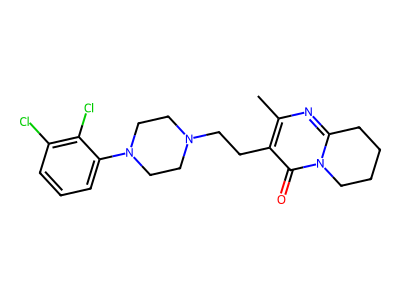

In [67]:
# Fixed example ligand from the scaffold prediction set (rank 5 in the current table)
LIGAND_NAME = "scaffold_example_s2230_14934458"
LIGAND_SMILES = "CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl"

# Write the SMILES to a file, which is what the docking code reads
LIGAND_FILE = ROOT / "docking" / "examples" / "drd2" / f"{LIGAND_NAME}.smi"
LIGAND_FILE.parent.mkdir(parents=True, exist_ok=True)
LIGAND_FILE.write_text(LIGAND_SMILES + "\n", encoding="ascii")

# Show the molecule to confirm the SMILES is the intended compound
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

molecule = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"{LIGAND_NAME}: {Chem.MolToSmiles(molecule)}")
drawer = rdMolDraw2D.MolDraw2DSVG(400, 300)
drawer.DrawMolecule(molecule)
drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

In [68]:
def main(ligand_path) -> int:
    try:
        tools = require_dependencies()
        raw_path = str(ligand_path).strip().strip('"')
        if not raw_path:
            raise ValueError("No ligand file was provided.")
        ligand_source = Path(raw_path.replace("\\", "/")).expanduser().resolve()
        if not ligand_source.is_file():
            raise FileNotFoundError(f"Ligand file not found: {ligand_source}")

        run_name = ligand_source.stem
        run_dir = RUN_DIR / run_name
        run_dir.mkdir(parents=True, exist_ok=True)

        center, size = prepare_shared_receptor(tools)
        for source_path in (RAW_STRUCTURE_PATH, SODIUM_STRUCTURE_PATH):
            shutil.copyfile(source_path, run_dir / source_path.name)
        for filename in (
            "drd2_clean.pdb",
            "drd2_repaired.pdb",
            "drd2.pdbqt",
        ):
            shutil.copyfile(SHARED_RECEPTOR_DIR / filename, run_dir / filename)

        receptor_pdbqt = run_dir / "drd2.pdbqt"
        ligand_sdf = run_dir / "ligand_3d.sdf"
        ligand_pdbqt = run_dir / "ligand.pdbqt"
        output_path = run_dir / "docked_poses.pdbqt"
        log_path = run_dir / "vina.log"

        create_ligand_sdf(ligand_source, ligand_sdf)
        run_preparation(
            [
                tools["mk_prepare_ligand.py"],
                "-i", str(ligand_sdf),
                "-o", str(ligand_pdbqt),
            ],
            "ligand",
        )

        dock(receptor_pdbqt, ligand_pdbqt, output_path, log_path, center, size)
        print(f"Docking poses: {output_path}")
        print(f"Vina log: {log_path}")
        print(
            "Note: this is a docking score, not an experimental binding affinity. "
            "Review the receptor preparation and pose before interpreting it."
        )
        return 0
    except (RuntimeError, ValueError, FileNotFoundError, subprocess.CalledProcessError) as exc:
        print(f"Docking could not be completed: {exc}", file=sys.stderr)
        return 1

In [69]:
main(LIGAND_FILE)

Docking could not be completed: This notebook is configured for Linux or macOS and explicitly rejects native Windows. Use a Linux/macOS kernel (WSL 2 Ubuntu is recommended on Windows), install the notebook dependencies in that environment, and run the notebook with its kernel.


1

# Batch docking: the top 100 scaffold and random compounds

The cells above dock a single ligand. This section docks the **top 100 compounds by predicted
pIC50** from each of the two ZINC22-derived datasets: 1,648 compounds from a similarity search
using default settings and 10,000 compounds from the random search query.
The ML ranking can then be compared with the docking ranking separately for each set.

The notebook selects up to 100 compounds per set and attempts to dock each one. Both sets use the same prepared receptor, docking box, exhaustiveness, and number of poses. Per-ligand files are separated under `docking/runs/batch_top100_scaffold/` and `docking/runs/batch_top100_random/`. Successful scores are summarized in `results/tables/top100_docking_results_scaffold.csv` and `results/tables/top100_docking_results_random.csv`; comparison plots go to `results/figures/`. The shared processed receptor with artificial Na+ is cached in `docking/prepared/6CM4_Na/`.

In [70]:
import pandas as pd

RESULTS_DIR = ROOT / "results" / "tables"
FIGURES_DIR = ROOT / "results" / "figures"

N_COMPOUNDS = 100
PREDICTION_FILES = {
    "scaffold": RESULTS_DIR / "scaffold_zinc22_predicted_pIC50.csv",
    "random": RESULTS_DIR / "random_zinc22_predicted_pIC50.csv",
}
BATCH_DIRS = {
    dataset_name: RUN_DIR / f"batch_top{N_COMPOUNDS}_{dataset_name}"
    for dataset_name in PREDICTION_FILES
}

top_compounds_by_dataset = {}
for dataset_name, predictions_path in PREDICTION_FILES.items():
    if not predictions_path.is_file():
        raise FileNotFoundError(f"{dataset_name} prediction file not found: {predictions_path}")
    predictions = pd.read_csv(predictions_path)
    required_columns = {"compound_id", "smiles", "pred_pIC50"}
    missing_columns = required_columns - set(predictions.columns)
    if missing_columns:
        raise ValueError(f"Missing prediction columns in {predictions_path}: {sorted(missing_columns)}")
    top_compounds = predictions.nlargest(N_COMPOUNDS, "pred_pIC50").reset_index(drop=True)
    if top_compounds.empty:
        raise ValueError(f"No compounds available to dock in {predictions_path}")
    top_compounds_by_dataset[dataset_name] = top_compounds
    BATCH_DIRS[dataset_name].mkdir(parents=True, exist_ok=True)
    print(
        f"{dataset_name}: {len(top_compounds)} compounds; predicted pIC50 range "
        f"{top_compounds['pred_pIC50'].min():.2f} - {top_compounds['pred_pIC50'].max():.2f}"
    )

[(name, compounds[["compound_id", "smiles", "pred_pIC50"]].head())
 for name, compounds in top_compounds_by_dataset.items()]

scaffold: 100 compounds; predicted pIC50 range 7.10 - 7.81
random: 100 compounds; predicted pIC50 range 6.43 - 6.91


[('scaffold',
                    compound_id  \
  0  s_2230__17793196__16949512   
  1  s_2230__12304850__16949512   
  2    s_2230__665554__16949512   
  3   s_2230__9292524__16949512   
  4  s_2230__14934458__16949512   
  
                                                smiles  pred_pIC50  
  0  CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...    7.812313  
  1  CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...    7.784896  
  2     COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C    7.778951  
  3  CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...    7.767475  
  4  CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...    7.729491  ),
 ('random',
          compound_id                                             smiles  \
  0  ZINCtQ00000Sk0Ja  Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=NC[C@H]3CCCS...   
  1  ZINCtQ00000Sk0Jb  Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=N[C@@H]3CC[C...   
  2  ZINCtl00001UEXnE  CN1CCC[C@H](CNc2c(NC[C@@H]3CCN(C)c4ccccc43)c(=...   
  3  ZINCtT00000Sk0J9  Fc1cccc2[nH]c(=NCC

In [71]:
def dock_one_smiles(smiles, name, batch_dir, tools, receptor_pdbqt, center, size):
    """Dock a single SMILES against the shared receptor. Returns the best Vina score."""
    ligand_sdf = batch_dir / f"{name}_3d.sdf"
    ligand_pdbqt = batch_dir / f"{name}.pdbqt"
    poses_pdbqt = batch_dir / f"{name}_poses.pdbqt"
    log_path = batch_dir / f"{name}.log"

    # Same preparation as the single-ligand run: write the SMILES to a file first
    smi_path = batch_dir / f"{name}.smi"
    smi_path.write_text(smiles + "\n", encoding="ascii")
    create_ligand_sdf(smi_path, ligand_sdf)

    subprocess.run(
        [tools["mk_prepare_ligand.py"], "-i", str(ligand_sdf), "-o", str(ligand_pdbqt)],
        check=True, capture_output=True,
    )

    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0, verbosity=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
    vina.write_poses(str(poses_pdbqt), n_poses=NUM_MODES, overwrite=True)

    # The best score is stored in the first pose of the output file
    for line in poses_pdbqt.read_text().splitlines():
        if line.startswith("REMARK VINA RESULT:"):
            return float(line.split()[3])
    return None

In [53]:
%%time
tools = require_dependencies()
center, size = prepare_shared_receptor(tools)
receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

docking_compounds_by_dataset = {}
for dataset_name, top_compounds in top_compounds_by_dataset.items():
    batch_dir = BATCH_DIRS[dataset_name]
    print(f"\nDocking top {len(top_compounds)} {dataset_name} compounds")
    scores = []
    for i, row in top_compounds.iterrows():
        try:
            score = dock_one_smiles(
                row["smiles"], row["compound_id"], batch_dir, tools,
                receptor_pdbqt, center, size,
            )
        except (ValueError, subprocess.CalledProcessError) as exc:
            print(f"  {row['compound_id']}: failed ({exc})")
            score = None
        scores.append(score)
        if (i + 1) % 10 == 0:
            print(f"  docked {i + 1}/{len(top_compounds)}")

    top_compounds = top_compounds.copy()
    top_compounds["vina_score"] = scores
    docking_compounds_by_dataset[dataset_name] = top_compounds
    print(
        f"Docked {top_compounds['vina_score'].notna().sum()} of "
        f"{len(top_compounds)} {dataset_name} compounds"
    )

CPU times: total: 0 ns
Wall time: 0 ns


RuntimeError: This notebook is configured for Linux or macOS and explicitly rejects native Windows. Use a Linux/macOS kernel (WSL 2 Ubuntu is recommended on Windows), install the notebook dependencies in that environment, and run the notebook with its kernel.

## Results: ML ranking vs docking ranking

Vina docking scores and model-predicted pIC50 are different quantities and should not be combined arithmetically. The tables and plots compare their rankings for prioritization only; neither score is an experimental binding measurement.

In [ ]:
docking_results_by_dataset = {}
for dataset_name, top_compounds in docking_compounds_by_dataset.items():
    results = top_compounds.dropna(subset=["vina_score"]).copy()
    results["ml_rank"] = results["pred_pIC50"].rank(ascending=False, method="min").astype(int)
    results["docking_rank"] = results["vina_score"].rank(ascending=True, method="min").astype(int)

    out_csv = RESULTS_DIR / f"top{N_COMPOUNDS}_docking_results_{dataset_name}.csv"
    results.to_csv(out_csv, index=False)
    docking_results_by_dataset[dataset_name] = results
    print(f"{dataset_name}: wrote {len(results)} docking results to {out_csv}")
    print(f"Best 10 {dataset_name} compounds by Vina score:")
    display_columns = ["compound_id", "pred_pIC50", "ml_rank", "vina_score", "docking_rank"]
    print(results.nsmallest(10, "vina_score")[display_columns].to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

for dataset_name, results in docking_results_by_dataset.items():
    if len(results) < 2:
        print(f"{dataset_name}: at least two successful docking results are needed for correlation.")
        continue
    rho, pvalue = spearmanr(results["pred_pIC50"], results["vina_score"])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(results["pred_pIC50"], results["vina_score"], s=25, alpha=0.7)
    ax.set_xlabel("predicted pIC50 (ML)")
    ax.set_ylabel("Vina score (kcal/mol)")
    ax.set_title(
        f"{dataset_name.title()} set: ML vs docking\n"
        f"Spearman rho = {rho:.2f} (p = {pvalue:.3f})"
    )
    ax.invert_yaxis()  # more negative (better) docking scores at the top
    fig.savefig(
        FIGURES_DIR / f"ml_vs_docking_{dataset_name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(
        f"{dataset_name}: Spearman correlation between ML and docking rankings: "
        f"rho = {rho:.2f}, p = {pvalue:.3f}"
    )